# Cvičenie III - Viacrozmerné a stavové modely

## Viacrozmerné časové rady a ich analýza

Kým jednorozmerný časový rad sleduje vývoj jednej premennej, napríklad ceny akcie, viacrozmerný sleduje súčasne dve alebo viac premenných, ako napríklad ceny viacerých akcií, vývoj inflácie a úrokových sadzieb alebo vzťah medzi spotrebou a príjmom domácností.

Hlavnou myšlienkou viacrozmernej analýzy je, že vývoj jednej premennej môže súvisieť nielen s jej vlastnou minulosťou, ale aj s minulými hodnotami ostatných premenných.

----------
### CCF

Pri analýze viacrozmerných časových radov nás zaujíma nielen vývoj jednotlivých premenných, ale aj ich vzájomné vzťahy v čase. Jedným zo spôsobov, ako tieto vzťahy skúmať je krížová korelačná funkcia (CCF).

Funkcia umožňuje skúmať lineárnu závislosť medzi dvoma časovými radmi pri rôznych časových lagoch. Postupne porovnávame hodnoty jednej premennej s časovo posunutými hodnotami druhej premennej a sledujeme, pri ktorých oneskoreniach je ich vzájomná korelácia najvýraznejšia.

$$
\rho_{XY}(h) = \operatorname{Corr}(X_t, Y_{t-h})
$$

Predpokladajme, že pozorujeme nasledujúce denné dáta:

| Deň | Reklama ($X$) | Tržby ($Y$) |
| :---: | :---: | :---: |
| **1** | 10 | 0 |
| **2** | 0 | 0 |
| **3** | 0 | 10 |
| **4** | 20 | 0 |
| **5** | 0 | 0 |
| **6** | 0 | 20 |
| **7** | 15 | 0 |
| **8** | 0 | 0 |
| **9** | 0 | 15 |

* Reklama v čase $t$ sa prejaví na tržbách presne o **2 dni neskôr** ($t+2$).



In [3]:
# TODO:
# 1. Pomocou knižnice yfinance načítajte denné ceny ETF pre XLK, XLV, SMH, SOXX, FXE, XLY
#    za obdobie od 1. 1. 2025 do 30. 9. 2026.
##
# 3. Vypočítajte a zobrazte CCF pre lagy od -15 do +15 pre tieto dvojice:
#    - XLK a XLV
#    - SMH a SOXX
#    - FXE a XLY
# Záporné aj kladné lagy zobrazte
#    v jednom grafe.
#
# 4. Pre každú dvojicu identifikujte lag, pri ktorom
#    absolútna hodnota CCF dosahuje maximum.
#    Pri hľadaní maxima nezabudnite zahrnúť aj lag 0.
#
# 5. Vysvetlite, prečo samotná krížová korelácia
#    nedokazuje kauzálny vzťah medzi premennými.

Downloaded price data:
Ticker            FXE         SMH        SOXX         XLK         XLV  \
Date                                                                    
2025-01-02  93.230949  244.030670  214.925766  114.852669  133.575211   
2025-01-03  93.634720  251.098694  220.526398  116.724205  134.885620   
2025-01-06  94.412712  259.422791  226.910126  118.209579  134.943848   
2025-01-07  94.008957  253.251968  223.817368  115.837967  135.613602   
2025-01-08  93.772583  251.447586  221.587021  115.798347  136.312500   

Ticker             XLY  
Date                    
2025-01-02  109.072372  
2025-01-03  111.279434  
2025-01-06  111.717888  
2025-01-07  109.555161  
2025-01-08  109.865532  

Date range: 2025-01-02 to 2026-09-30

Number of observations:
Ticker
FXE     437
SMH     437
SOXX    437
XLK     437
XLV     437
XLY     437
dtype: int64


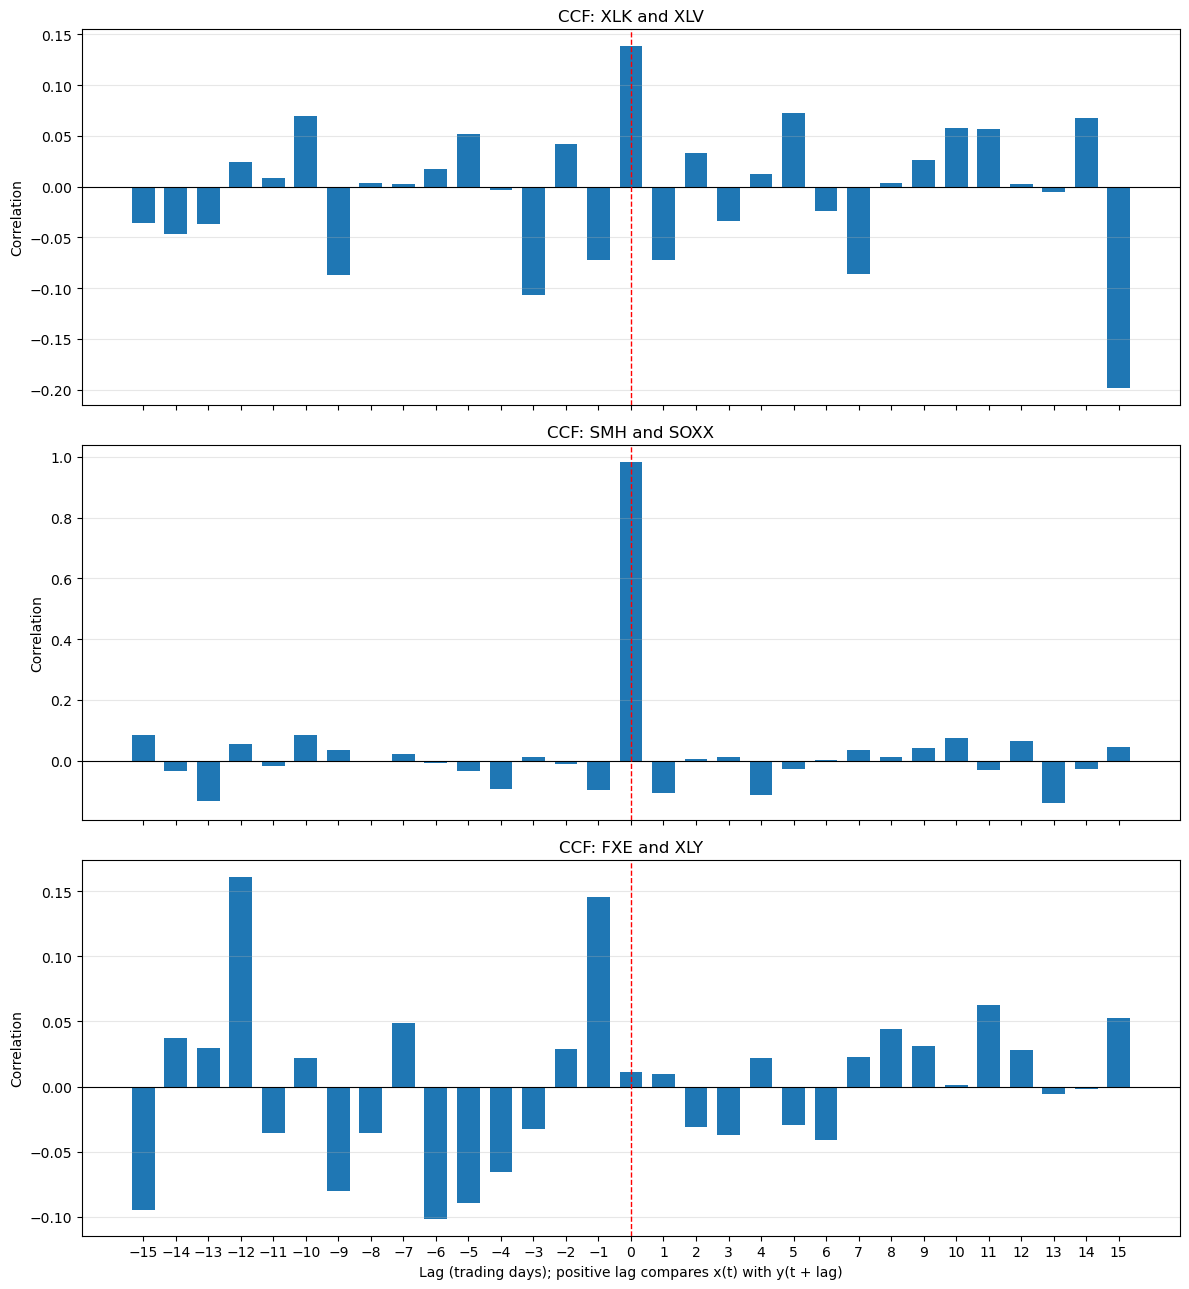


Maximum absolute cross-correlation for each pair:
XLK and XLV: lag = 15, CCF = -0.1981, absolute CCF = 0.1981
SMH and SOXX: lag = 0, CCF = 0.9833, absolute CCF = 0.9833
FXE and XLY: lag = -12, CCF = 0.1607, absolute CCF = 0.1607


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# 1. Download daily ETF prices
tickers = ["XLK", "XLV", "SMH", "SOXX", "FXE", "XLY"]

prices = yf.download(
    tickers,
    start="2025-01-01",
    end="2026-10-01",
    auto_adjust=True,
    progress=False
)["Close"]

prices = prices.sort_index()

print("Downloaded price data:")
print(prices.head())
print("\nDate range:", prices.index.min().date(), "to", prices.index.max().date())
print("\nNumber of observations:")
print(prices.count())

# 2. Calculate daily percentage returns
returns = prices.pct_change(fill_method=None).dropna(how="all")

# Define the ETF pairs
pairs = [
    ("XLK", "XLV"),
    ("SMH", "SOXX"),
    ("FXE", "XLY")
]

# 3. Calculate cross-correlation for lags from -15 to +15
# Convention: lag k measures corr(x_t, y_(t+k)).
# Lag 0 is the contemporaneous correlation.

def calculate_ccf(x, y, max_lag=15):
    results = {}

    for lag in range(-max_lag, max_lag + 1):
        if lag > 0:
            aligned = pd.concat(
                [x.iloc[:-lag].reset_index(drop=True),
                 y.iloc[lag:].reset_index(drop=True)],
                axis=1
            )
        elif lag < 0:
            aligned = pd.concat(
                [x.iloc[-lag:].reset_index(drop=True),
                 y.iloc[:lag].reset_index(drop=True)],
                axis=1
            )
        else:
            aligned = pd.concat(
                [x.reset_index(drop=True),
                 y.reset_index(drop=True)],
                axis=1
            )

        aligned = aligned.dropna()
        results[lag] = aligned.iloc[:, 0].corr(aligned.iloc[:, 1])

    return pd.Series(results, dtype=float)


# 4. Plot all three pairs in one figure
fig, axes = plt.subplots(3, 1, figsize=(12, 13), sharex=True)

ccf_results = {}

for ax, (etf1, etf2) in zip(axes, pairs):
    pair_returns = returns[[etf1, etf2]].dropna()

    ccf_values = calculate_ccf(
        pair_returns[etf1],
        pair_returns[etf2],
        max_lag=15
    )

    ccf_results[(etf1, etf2)] = ccf_values

    ax.bar(
        ccf_values.index,
        ccf_values.values,
        width=0.7
    )
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"CCF: {etf1} and {etf2}")
    ax.set_ylabel("Correlation")
    ax.set_xticks(range(-15, 16))
    ax.grid(axis="y", alpha=0.3)

axes[-1].set_xlabel(
    "Lag (trading days); positive lag compares x(t) with y(t + lag)"
)

plt.tight_layout()
plt.show()

# 5. Identify the lag with the maximum absolute CCF,
# including lag 0
print("\nMaximum absolute cross-correlation for each pair:")

for (etf1, etf2), ccf_values in ccf_results.items():
    valid_ccf = ccf_values.dropna()

    if valid_ccf.empty:
        print(f"{etf1} and {etf2}: insufficient data")
        continue

    best_lag = valid_ccf.abs().idxmax()
    best_corr = valid_ccf.loc[best_lag]

    print(
        f"{etf1} and {etf2}: "
        f"lag = {best_lag}, "
        f"CCF = {best_corr:.4f}, "
        f"absolute CCF = {abs(best_corr):.4f}"
    )


-------
### Kointegrácia

Pri analýze časových radov mnohé premenné vykazujú v čase trend, čo znamená, že sú nestacionárne. Táto nestacionarita môže predstavovať problém pri tvorbe štatistických modelov, pretože môže viesť k zavádzajúcim výsledkom. Niekedy sa však dva alebo viaceré nestacionárne časové rady vyvíjajú spoločne takým spôsobom, že ich kombinácia je stacionárna. Tento vzťah nazývame kointegrácia.


Johansenov test slúži na overenie existencie dlhodobých vzťahov medzi viacerými nestacionárnymi časovými radmi, ktoré sú integrované rádu $I(1)$. Test určuje počet nezávislých kointegračných vzťahov, tzv. kointegračný rank $r$.


Pri troch časových radoch testujeme postupne tieto hypotézy:
| Nulová hypotéza $H_0$ |
|---|
| $r = 0$ | 
| $r \leq 1$ | 
| $r \leq 2$ |

- $r = 0$: neidentifikovali sme žiadny kointegračný vzťah.
- $r = 1$: existuje jeden kointegračný vzťah.
- $r = 2$: existujú dva nezávislé kointegračné vzťahy.
- $r = 3$: plný rank.

Pri testovaní používame pôvodné cenové úrovne alebo ich logaritmy, nie prvé diferencie a kointegračný rank určujeme podľa prvej nezamietnutej hypotézy.

| Situácia | Model 
| :--- | :--- |
| Rady sú stacionárne, $I(0)$ | **VAR v úrovniach** *(VAR in levels)* |
| Rady sú nestacionárne, $I(1)$, a **nie sú** kointegrované | **VAR v prvých diferenciách** *(VAR in differences)* | 
| Rady sú nestacionárne, $I(1)$, a **sú** kointegrované | **VECM** *(Vector Error Correction Model)* |


In [6]:
# TODO:
# 1. Pomocou yfinance načítajte denné ceny ETF
#    za obdobie od 1. 1. 2020 do 30. 9. 2026 pre tieto trojice:
#    -  SPY, IVV, VOO
#    -  SPY, GLD, TLT
#
# 2. Pomocou ADF testu overte stacionaritu jednotlivých
#    časových radov.
#
# 3. Na pôvodné cenové úrovne aplikujte Johansenov
#    kointegračný test.
#    Použite det_order=0 a k_ar_diff=1.
#
# 4. Určte kointegračný rank r pre každú skupinu.
#
# 5. Na základe ADF a Johansenovho testu rozhodnite,
#    či je pre danú skupinu vhodnejší VAR
#    na prvých diferenciách alebo VECM.


import warnings
import numpy as np
import pandas as pd
import yfinance as yf

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen

warnings.filterwarnings("ignore")

# 1. Download daily adjusted ETF prices
groups = {
    "SPY, IVV, VOO": ["SPY", "IVV", "VOO"],
    "SPY, GLD, TLT": ["SPY", "GLD", "TLT"]
}

start_date = "2020-01-01"
end_date = "2026-10-01"  # End date is exclusive

all_tickers = sorted(set(
    ticker for group in groups.values() for ticker in group
))

data = yf.download(
    all_tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

prices = data["Close"].copy()
prices = prices.dropna(how="all").sort_index()

print("Downloaded data:")
print("First date:", prices.index.min().date())
print("Last date:", prices.index.max().date())
print("Number of observations per ETF:")
print(prices.count())


# 2. ADF test helper
def run_adf(series, label, alpha=0.05):
    series = series.dropna()

    result = adfuller(series, autolag="AIC")

    statistic = result[0]
    p_value = result[1]
    critical_value = result[4]["5%"]

    stationary = p_value < alpha

    return {
        "Series": label,
        "ADF statistic": statistic,
        "p-value": p_value,
        "5% critical value": critical_value,
        "Stationary at 5%": stationary
    }


# 3. ADF tests on levels and first differences
adf_results = []

for group_name, tickers in groups.items():
    group_prices = prices[tickers].dropna()

    for ticker in tickers:
        adf_results.append(
            run_adf(group_prices[ticker], f"{ticker} (level)")
        )

        adf_results.append(
            run_adf(
                group_prices[ticker].diff().dropna(),
                f"{ticker} (first difference)"
            )
        )

adf_table = pd.DataFrame(adf_results)

print("\nADF test results:")
print(adf_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


# 4. Johansen cointegration test on price levels
# det_order=0 and k_ar_diff=1 as required
johansen_results = {}

for group_name, tickers in groups.items():
    group_prices = prices[tickers].dropna()

    johansen = coint_johansen(
        group_prices,
        det_order=0,
        k_ar_diff=1
    )

    # Trace test at the 5% significance level
    trace_statistics = johansen.lr1
    trace_critical_values = johansen.cvt[:, 1]

    # Sequential rank selection:
    # Reject H0 for each rank while the trace statistic exceeds
    # its 5% critical value. Stop at the first non-rejection.
    rank = 0

    for statistic, critical_value in zip(
        trace_statistics, trace_critical_values
    ):
        if statistic > critical_value:
            rank += 1
        else:
            break

    johansen_results[group_name] = {
        "rank": rank,
        "trace_statistics": trace_statistics,
        "trace_critical_values": trace_critical_values
    }

    print(f"\nJohansen test: {group_name}")
    print("Rank hypotheses: r = 0, r <= 1, r <= 2")
    print("Trace statistics:", np.round(trace_statistics, 4))
    print("5% critical values:", np.round(trace_critical_values, 4))
    print("Estimated cointegration rank:", rank)


# 5. Recommend VAR on differences or VECM
print("\nMODEL RECOMMENDATIONS")

for group_name, tickers in groups.items():
    group_prices = prices[tickers].dropna()

    level_results = [
        adfuller(group_prices[ticker], autolag="AIC")[1]
        for ticker in tickers
    ]

    diff_results = [
        adfuller(group_prices[ticker].diff().dropna(), autolag="AIC")[1]
        for ticker in tickers
    ]

    levels_nonstationary = all(p > 0.05 for p in level_results)
    differences_stationary = all(p < 0.05 for p in diff_results)

    rank = johansen_results[group_name]["rank"]

    print(f"\n{group_name}")
    print("All levels non-stationary:", levels_nonstationary)
    print("All first differences stationary:", differences_stationary)
    print("Johansen rank:", rank)

    if levels_nonstationary and differences_stationary:
        if 0 < rank < len(tickers):
            print(
                "Recommendation: VECM, because the series appear "
                "I(1) and cointegrated."
            )
        elif rank == 0:
            print(
                "Recommendation: VAR on first differences, because "
                "no cointegration was detected."
            )
        elif rank == len(tickers):
            print(
                "Caution: full rank suggests stationary levels under "
                "the test specification; reconsider a VAR in levels."
            )
        else:
            print(
                "Caution: inspect the test results and integration "
                "orders before choosing a model."
            )
    else:
        print(
            "Caution: the standard I(1) decision rule is not clearly "
            "satisfied. Review the ADF results before selecting VAR "
            "on differences or VECM."
        )


Downloaded data:
First date: 2020-01-02
Last date: 2026-09-30
Number of observations per ETF:
Ticker
GLD    1695
IVV    1695
SPY    1695
TLT    1695
VOO    1695
dtype: int64

ADF test results:
                Series  ADF statistic  p-value  5% critical value  Stationary at 5%
           SPY (level)         0.4613   0.9836            -2.8633             False
SPY (first difference)       -13.8828   0.0000            -2.8633              True
           IVV (level)         0.4648   0.9838            -2.8633             False
IVV (first difference)       -13.8433   0.0000            -2.8633              True
           VOO (level)         0.4601   0.9836            -2.8633             False
VOO (first difference)       -13.8043   0.0000            -2.8633              True
           SPY (level)         0.4613   0.9836            -2.8633             False
SPY (first difference)       -13.8828   0.0000            -2.8633              True
           GLD (level)         0.0307   0.9610     

Training period: 2020-01-02 to 2026-06-29
Test period: 2026-06-30 to 2026-09-30
Training observations: 1630
Test observations: 65

Information criteria:
 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        5.898      5.908*       364.4      5.902*
1        5.894       5.934       363.0       5.909
2        5.877       5.947       356.7       5.903
3        5.870       5.970       354.2       5.907
4        5.871       6.001       354.6       5.919
5        5.875       6.035       356.1       5.934
6        5.877       6.066       356.6       5.947
7        5.879       6.098       357.3       5.960
8        5.873       6.123       355.5       5.966
9       5.868*       6.148      353.6*       5.972
10       5.872       6.182       355.0       5.987
--------------------------------------------------

Selected lag order by AIC: 9

VAR model summary:
  Summary of Regression Results 

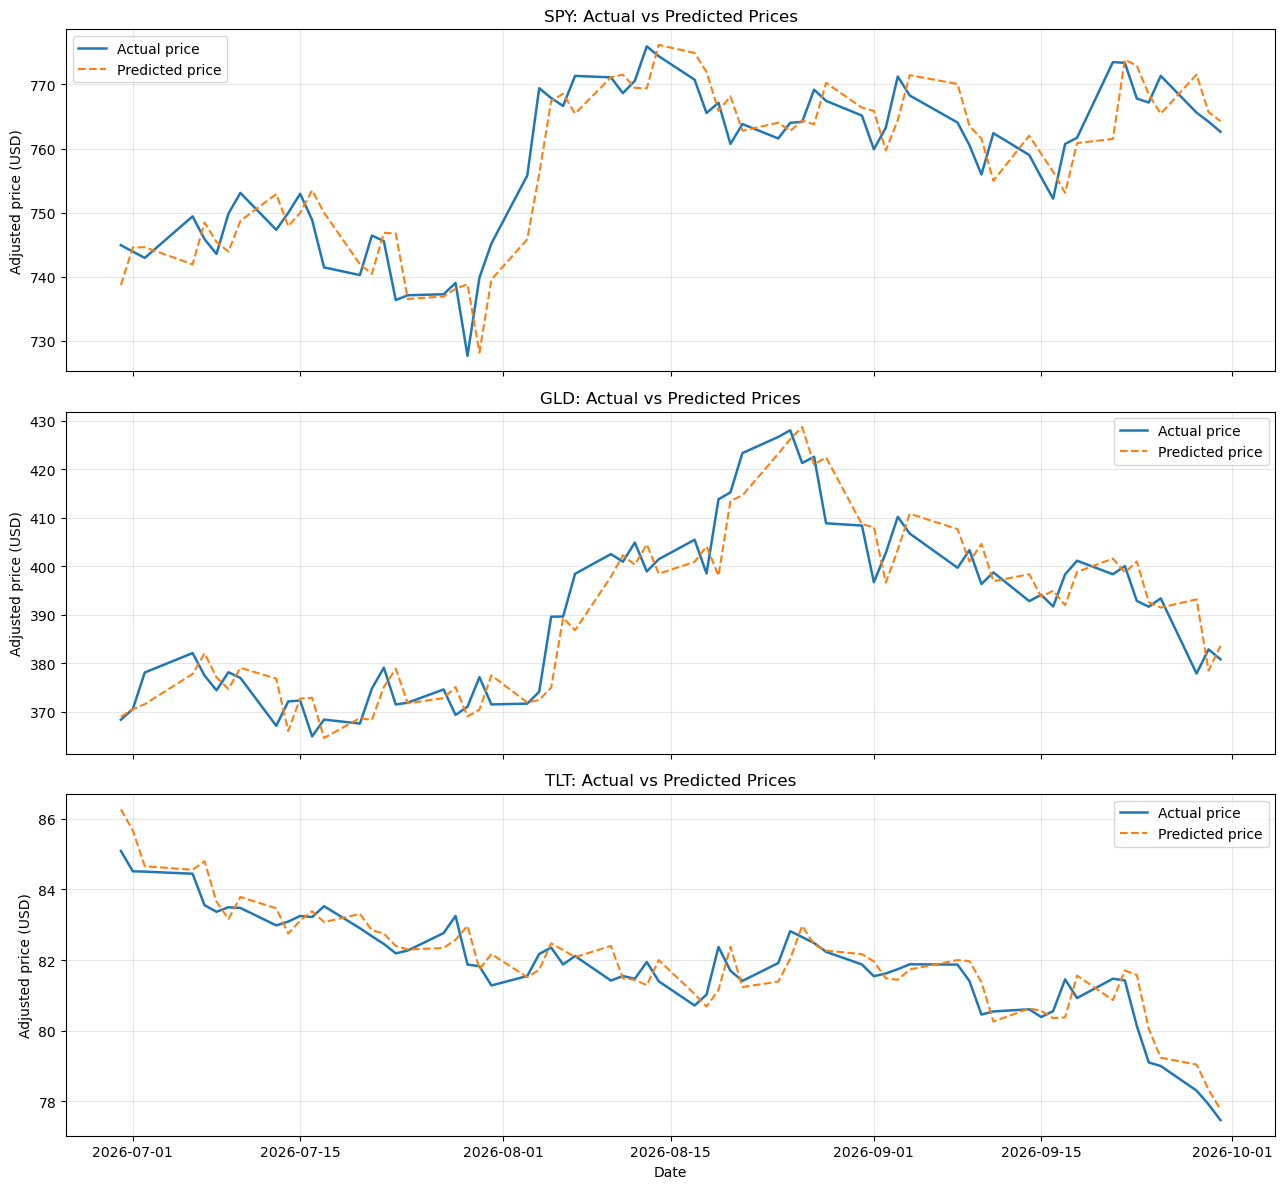


Rolling-origin one-day-ahead RMSE:
SPY: RMSE = 5.3523 USD
GLD: RMSE = 6.1107 USD
TLT: RMSE = 0.5688 USD

First rows of actual and predicted prices:
Ticker      SPY_actual  GLD_actual  TLT_actual  SPY_predicted  GLD_predicted  \
Date                                                                           
2026-06-30  744.920227  368.380005   85.086494     738.698222     369.005049   
2026-07-01  743.912720  370.600006   84.511368     744.557677     370.548377   
2026-07-02  742.935181  378.130005   84.501488     744.606244     371.603300   
2026-07-06  749.419067  382.130005   84.442192     741.929524     377.816862   
2026-07-07  745.857910  377.489990   83.552811     748.461998     382.080808   

Ticker      TLT_predicted  
Date                       
2026-06-30      86.266565  
2026-07-01      85.664268  
2026-07-02      84.655016  
2026-07-06      84.553420  
2026-07-07      84.794316  


In [8]:
# TODO:
# 1. Rozdeľte dáta na trénovaciu množinu a testovaciu
#    množinu, ktorú tvoria posledné 3 mesiace.
#
# 2. Vytvorte VAR model pre SPY, GLD a TLT
#    na prvých diferenciách cien.
#
# 3. Pomocou AIC vyberte počet lagov
#    na trénovacích dátach - skúšajte od 0 do 10. 
#
# 4. Overte stabilitu modelu pomocou is_stable().
#
# 5. Vykonajte rolling-origin predikciu s horizontom 1 deň.
#
# 6. Predikované prvé diferencie preveďte späť
#     na pôvodné cenové úrovne.
#
# 7. Vykreslite skutočné a predikované ceny
#     ETF SPY, GLD a TLT počas testovacieho obdobia.
#
# 8. Vypočítajte RMSE predikcie pre každé ETF.


import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from statsmodels.tsa.api import VAR
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

# 1. Download daily adjusted prices
tickers = ["SPY", "GLD", "TLT"]

prices = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-10-01",
    auto_adjust=True,
    progress=False
)["Close"]

prices = prices[tickers].dropna().sort_index()

if len(prices) < 100:
    raise ValueError("Insufficient price data to fit the VAR model.")

# 2. Split into training and test sets
# Use the last three calendar months as the test period.
test_start = prices.index.max() - pd.DateOffset(months=3)

train_prices = prices.loc[prices.index < test_start]
test_prices = prices.loc[prices.index >= test_start]

print("Training period:", train_prices.index.min().date(),
      "to", train_prices.index.max().date())
print("Test period:", test_prices.index.min().date(),
      "to", test_prices.index.max().date())
print("Training observations:", len(train_prices))
print("Test observations:", len(test_prices))

if len(test_prices) == 0:
    raise ValueError("The test set is empty.")

# 3. Calculate first differences of prices
train_diff = train_prices.diff().dropna()

# Select the lag order using AIC, trying lags 0 through 10.
# VAR requires at least one lag in the fitted model, so
# the practical search starts at lag 1.
model_selection = VAR(train_diff)
selection = model_selection.select_order(maxlags=10)

print("\nInformation criteria:")
print(selection.summary())

selected_lag = selection.selected_orders["aic"]

if selected_lag is None or selected_lag < 1:
    selected_lag = 1

print("\nSelected lag order by AIC:", selected_lag)

# 4. Fit VAR model and check stability
var_model = VAR(train_diff)
var_result = var_model.fit(selected_lag)

is_stable = var_result.is_stable()

print("\nVAR model summary:")
print(var_result.summary())
print("\nModel is stable:", is_stable)

# 5. Rolling-origin one-step-ahead forecast
# At each step, fit the model using only information
# available up to that date, then forecast the next day.
# The lag order selected on the original training set is kept fixed.

history = train_diff.copy()
predicted_diffs = []
forecast_dates = test_prices.index

for date in forecast_dates:
    rolling_model = VAR(history)
    rolling_result = rolling_model.fit(selected_lag)

    # Forecast the next daily price difference
    next_diff = rolling_result.forecast(
        y=history.values[-selected_lag:],
        steps=1
    )[0]

    predicted_diffs.append(next_diff)

    # Update history with the actual observed price difference
    # for the next forecast origin, without using future information.
    previous_date = prices.index[prices.index.get_loc(date) - 1]
    actual_diff = prices.loc[date] - prices.loc[previous_date]
    history.loc[date] = actual_diff

predicted_diffs = pd.DataFrame(
    predicted_diffs,
    index=forecast_dates,
    columns=tickers
)

# 6. Convert predicted first differences back to price levels
# Each forecast is one day ahead, so add the predicted difference
# to the actual price observed at the forecast origin.
previous_prices = prices.shift(1).loc[forecast_dates]
predicted_prices = previous_prices + predicted_diffs

actual_prices = test_prices[tickers]

# 7. Plot actual and predicted ETF prices
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)

for ax, ticker in zip(axes, tickers):
    ax.plot(
        actual_prices.index,
        actual_prices[ticker],
        label="Actual price",
        linewidth=1.8
    )
    ax.plot(
        predicted_prices.index,
        predicted_prices[ticker],
        label="Predicted price",
        linewidth=1.5,
        linestyle="--"
    )

    ax.set_title(f"{ticker}: Actual vs Predicted Prices")
    ax.set_ylabel("Adjusted price (USD)")
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

# 8. Calculate RMSE for each ETF
print("\nRolling-origin one-day-ahead RMSE:")

for ticker in tickers:
    rmse = np.sqrt(
        mean_squared_error(
            actual_prices[ticker],
            predicted_prices[ticker]
        )
    )

    print(f"{ticker}: RMSE = {rmse:.4f} USD")

# Display actual and predicted values in a table
comparison = pd.concat(
    [
        actual_prices.add_suffix("_actual"),
        predicted_prices.add_suffix("_predicted")
    ],
    axis=1
)

print("\nFirst rows of actual and predicted prices:")
print(comparison.head())


--------
### IRF

IRF ukazuje, ako systém reaguje na jednorazový šok v jednej premennej a ako sa tento účinok vyvíja v nasledujúcich obdobiach.

1. Znamienko odozvy: kladná hodnota znamená pozitívnu reakciu, záporná negatívnu.
2. Veľkosť odozvy: ako výrazne sa daná premenná zmení po šoku.
3. Trvanie odozvy: po koľkých obdobiach účinok približne zaniká.
4. Intervaly spoľahlivosti: či je nulová odozva zlučiteľná s odhadnutou neistotou.

    - Stĺpce predstavujú premennú, v ktorej nastal šok. 
    - Riadky predstavujú premennú, ktorej reakciu sledujeme.
    - Modrá čiara je odhadnutá impulzná odozva.
    - Čierne prerušované čiary predstavujú intervaly neistoty.

Parameter orth=True zabezpečuje výpočet ortogonalizovaných impulzných odoziev pomocou Choleského rozkladu, čím zobrazuje nekorelované šoky jednotlivých premenných. Orth=False zobrazuje korelované šoky.


Downloaded price data:
Ticker             SPY         GLD         TLT
Date                                          
2020-01-02  295.391785  143.949997  111.552559
2020-01-03  293.154938  145.860001  113.270554
2020-01-06  294.273376  147.389999  112.627304
2020-01-07  293.445984  147.970001  112.073624
2020-01-08  295.009918  146.860001  111.332764

Date range:
2020-01-02 to 2026-09-30

Lag order selection:
 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        5.898      5.908*       364.4      5.902*
1        5.894       5.934       363.0       5.909
2        5.877       5.947       356.7       5.903
3        5.870       5.970       354.2       5.907
4        5.871       6.001       354.6       5.919
5        5.875       6.035       356.1       5.934
6        5.877       6.066       356.6       5.947
7        5.879       6.098       357.3       5.960
8        5.873       6.123 

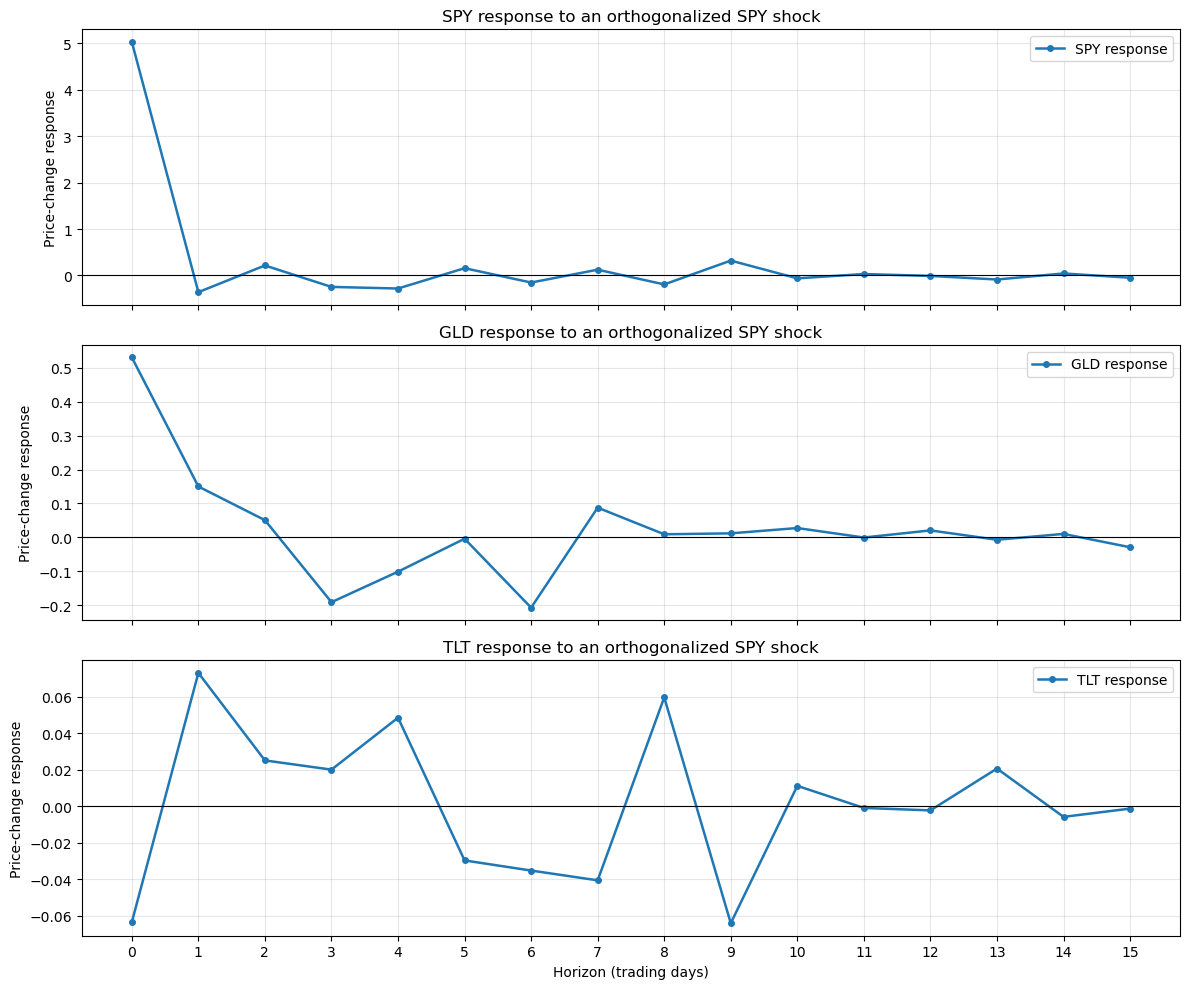


Orthogonalized impulse responses to a SPY shock:
              SPY       GLD       TLT
Horizon                              
0        5.027638  0.530145 -0.063470
1       -0.358607  0.149991  0.073100
2        0.215447  0.050894  0.025143
3       -0.245910 -0.190620  0.020096
4       -0.280393 -0.100813  0.048555
5        0.156727 -0.003785 -0.029663
6       -0.151358 -0.206787 -0.035208
7        0.124438  0.087680 -0.040574
8       -0.192263  0.009295  0.059655
9        0.320296  0.012048 -0.064061
10      -0.061672  0.027675  0.011207
11       0.031521 -0.000215 -0.000904
12      -0.009196  0.020683 -0.002236
13      -0.086615 -0.006808  0.020680
14       0.043615  0.010385 -0.005787
15      -0.048493 -0.028835 -0.001263

RESPONSE ANALYSIS

GLD:
  Initial response (day 0): 0.530145
  Peak response: -0.206787
  Peak horizon: 6 trading days
  Peak sign: negative
  Response on day 15: -0.028835
  Duration: returns within 5% of peak magnitude by day 8
  The response is smaller at day 15

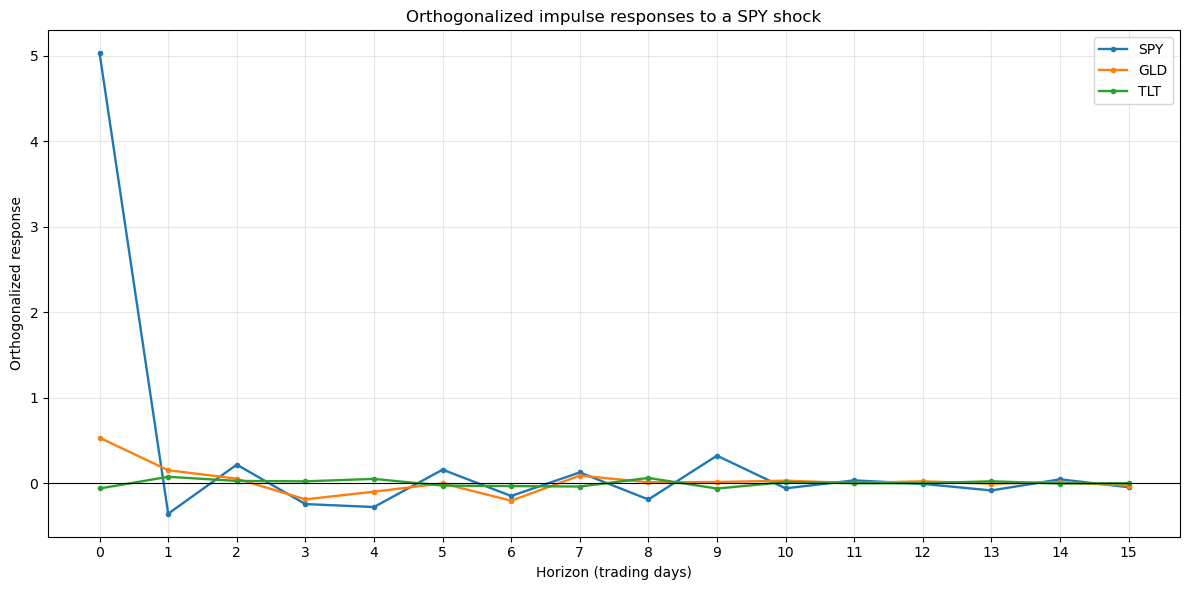

In [10]:

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from statsmodels.tsa.api import VAR

warnings.filterwarnings("ignore")

# 1. Download daily adjusted prices for SPY, GLD, and TLT
tickers = ["SPY", "GLD", "TLT"]

data = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-10-01",
    auto_adjust=True,
    progress=False
)

prices = data["Close"][tickers].dropna().sort_index()

if prices.empty:
    raise ValueError("No price data was downloaded. Check your internet connection.")

print("Downloaded price data:")
print(prices.head())
print("\nDate range:")
print(prices.index.min().date(), "to", prices.index.max().date())

# 2. Calculate first differences of prices
price_diff = prices.diff().dropna()

# 3. Split the data into training and test sets.
# The last three calendar months are reserved for testing.
test_start = prices.index.max() - pd.DateOffset(months=3)

train_prices = prices.loc[prices.index < test_start]
train_diff = train_prices.diff().dropna()

if len(train_diff) < 30:
    raise ValueError("Not enough training observations to estimate the VAR model.")

# 4. Select the lag order using AIC, testing lag orders from 1 to 10.
# A standard dynamic VAR model requires at least one lag.
max_lags = min(10, max(1, len(train_diff) // 10))

selection = VAR(train_diff).select_order(maxlags=max_lags)
selected_lag = selection.selected_orders["aic"]

if selected_lag is None or selected_lag < 1:
    selected_lag = 1

print("\nLag order selection:")
print(selection.summary())
print("\nSelected lag order by AIC:", selected_lag)

# 5. Fit the VAR model on the training first differences
var_model = VAR(train_diff)
var_result = var_model.fit(selected_lag)

print("\nModel variables:", var_result.names)
print("VAR model is stable:", var_result.is_stable())

# 6. Calculate orthogonalized impulse responses for 15 trading days
horizon = 15
irf = var_result.irf(horizon)

# Orthogonalized responses use a Cholesky decomposition.
# Variable ordering is SPY, GLD, TLT.
names = list(var_result.names)

if not all(ticker in names for ticker in tickers):
    raise ValueError(
        f"Expected variables {tickers}, but model contains {names}."
    )

spy_idx = names.index("SPY")

# irf.orth_irfs dimensions:
# (horizon + 1, response variable, impulse variable)
orthogonalized_responses = irf.orth_irfs

# 7. Plot responses of SPY, GLD, and TLT to a SPY shock
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
steps = np.arange(horizon + 1)

for ax, ticker in zip(axes, tickers):
    response_idx = names.index(ticker)

    values = orthogonalized_responses[
        :, response_idx, spy_idx
    ]

    ax.plot(
        steps,
        values,
        marker="o",
        markersize=4,
        linewidth=1.8,
        label=f"{ticker} response"
    )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{ticker} response to an orthogonalized SPY shock")
    ax.set_ylabel("Price-change response")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Horizon (trading days)")
axes[-1].set_xticks(steps)

plt.tight_layout()
plt.show()

# 8. Print numerical impulse responses
response_df = pd.DataFrame(
    {
        ticker: orthogonalized_responses[
            :, names.index(ticker), spy_idx
        ]
        for ticker in tickers
    },
    index=steps
)

response_df.index.name = "Horizon"

print("\nOrthogonalized impulse responses to a SPY shock:")
print(response_df.round(6).to_string())

# 9. Analyze sign, magnitude, and duration for GLD and TLT
print("\nRESPONSE ANALYSIS")

for ticker in ["GLD", "TLT"]:
    values = response_df[ticker].to_numpy()

    # Find the largest absolute response after the initial impact.
    peak_idx = 1 + np.argmax(np.abs(values[1:]))
    peak_value = values[peak_idx]

    sign = (
        "positive" if peak_value > 0
        else "negative" if peak_value < 0
        else "zero"
    )

    # Define a response as close to zero if its absolute value
    # is no more than 5% of the peak absolute response.
    threshold = 0.05 * abs(peak_value)

    near_zero = np.where(
        np.abs(values[peak_idx:]) <= threshold
    )[0]

    if abs(peak_value) < 1e-12:
        duration_text = "response is approximately zero"
    elif len(near_zero) > 0:
        duration_day = peak_idx + near_zero[0]
        duration_text = (
            f"returns within 5% of peak magnitude "
            f"by day {duration_day}"
        )
    else:
        duration_text = (
            "does not return within 5% of peak magnitude "
            "during the 15-day horizon"
        )

    print(f"\n{ticker}:")
    print(f"  Initial response (day 0): {values[0]:.6f}")
    print(f"  Peak response: {peak_value:.6f}")
    print(f"  Peak horizon: {peak_idx} trading days")
    print(f"  Peak sign: {sign}")
    print(f"  Response on day 15: {values[-1]:.6f}")
    print(f"  Duration: {duration_text}")

    if abs(values[-1]) < abs(peak_value):
        print("  The response is smaller at day 15 than at its peak.")
    else:
        print("  The response has not clearly declined from its peak.")

# 10. Plot the three responses together for direct comparison
plt.figure(figsize=(12, 6))

for ticker in tickers:
    plt.plot(
        response_df.index,
        response_df[ticker],
        marker="o",
        markersize=3,
        linewidth=1.7,
        label=ticker
    )

plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(steps)
plt.xlabel("Horizon (trading days)")
plt.ylabel("Orthogonalized response")
plt.title("Orthogonalized impulse responses to a SPY shock")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


--------
## Stavové modely

Stavové modely (State-Space Models) slúžia na modelovanie časových radov, pri ktorých predpokladáme existenciu skrytého (nepozorovateľného) stavu systému.

Pozorované hodnoty obsahujú informáciu o tomto stave, ale môžu byť ovplyvnené náhodným šumom.


### Matematický zápis stavového modelu

**1. Stavová rovnica – ako sa vyvíja skrytý stav:**

$$
x_t = Fx_{t-1} + w_t
$$

**2. Pozorovacia rovnica – čo v skutočnosti pozorujeme:**

$$
y_t = Hx_t + v_t
$$

kde:

- $x_t$ – skrytý (nepozorovateľný) stav systému,
- $y_t$ – pozorovaná hodnota časového radu,
- $F$ – určuje, ako aktuálny stav závisí od predchádzajúceho stavu,
- $H$ – určuje vzťah medzi skrytým stavom a pozorovaním,
- $w_t$ – stavový šum, teda náhodné zmeny samotného systému,
- $v_t$ – pozorovací šum, teda náhodná chyba merania.

Predpokladáme, že šumy majú nulovú strednú hodnotu, sú nezávislé a majú normálne rozdelenie:

$$
w_t \sim N(0,Q), \qquad v_t \sim N(0,R)
$$

Parametre $Q$ a $R$ predstavujú rozptyly jednotlivých šumov.

### AR(1) ako stavový model

Z predchádzajúcich cvičení poznáme autoregresný model prvého rádu:

$$
x_t = \phi x_{t-1} + w_t
$$

Ak tento proces nepozorujeme priamo, ale iba s náhodnou chybou, môžeme ho zapísať ako stavový model:

**Stavová rovnica:**

$$
x_t = \phi x_{t-1} + w_t
$$

**Pozorovacia rovnica:**

$$
y_t = x_t + v_t
$$

V porovnaní so všeobecným stavovým modelom platí:

$$
F = \phi, \qquad H = 1
$$

### Simulácia AR(1) stavového modelu

Použijeme nasledujúce parametre:

| Parameter |  Význam |
|---|---
| $n$ | Počet simulovaných časových okamihov |
| $\phi$ | Sila závislosti skrytého stavu od jeho minulosti |
| $Q$ | Rozptyl stavového šumu |
| $R$ | Rozptyl pozorovacieho šumu |

**3. Rozdiel medzi $Q$ a $R$**

- Väčšie $Q$ znamená väčšie náhodné zmeny **skutočného skrytého stavu**.
- Väčšie $R$ znamená väčšiu chybu **pozorovaných hodnôt**.

V reálnej situácii však spravidla poznáme iba pozorovania a skrytý stav nevieme priamo určiť.


In [11]:
# Stavová rovnica:       x_t = phi * x_(t-1) + w_t
# Pozorovacia rovnica:   y_t = x_t + v_t
#
# state        = skrytý stav systému
# observations = zašumené pozorovania

import numpy as np
import matplotlib.pyplot as plt

# 1. Parametre stavového modelu
rng = np.random.default_rng(42)

In [ ]:
# 1. Parametre stavového modelu
n = 200
phi = 0.8
Q = 0.5
R = 2.0

# 2. Simulácia skrytého AR(1) stavu
state = np.zeros(n)

for t in range(1, n):
    w_t = rng.normal(0, np.sqrt(Q))
    # TODO: Vypočítajte aktuálnu hodnotu skrytého stavu podľa stavovej rovnice AR(1).

# 3. Vytvorenie zašumených pozorovaní
v = rng.normal(0, np.sqrt(R), size=n)
observations = state + v

#4. Vizualizácia
plt.figure(figsize=(12, 5))

plt.plot(
    state,
    label="Skrytý AR(1) stav",
    linewidth=2
)

plt.scatter(
    range(n),
    observations,
    label="Zašumené pozorovania",
    alpha=0.4,
    s=15
)

plt.title("AR(1) ako stavový model")
plt.xlabel("Čas")
plt.ylabel("Hodnota")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# TODO 5: Experimentovanie s parametrami
#
# 1. Zmeňte phi z 0.8 na -0.8.
#    Ako sa zmení priebeh skrytého stavu?
#
# 2. Vráťte phi na 0.8 a zvýšte Q z 0.5 na 2.0.
#    Ako sa zmenia náhodné výkyvy skrytého stavu?
#
# 3. Vráťte Q na 0.5 a zvýšte R z 2.0 na 5.0.
#    Ako sa zmení rozdiel medzi skrytým stavom a pozorovaniami?
#
# Pri každom experimente meňte iba jeden parameter.
# Ostatné parametre ponechajte nezmenené.


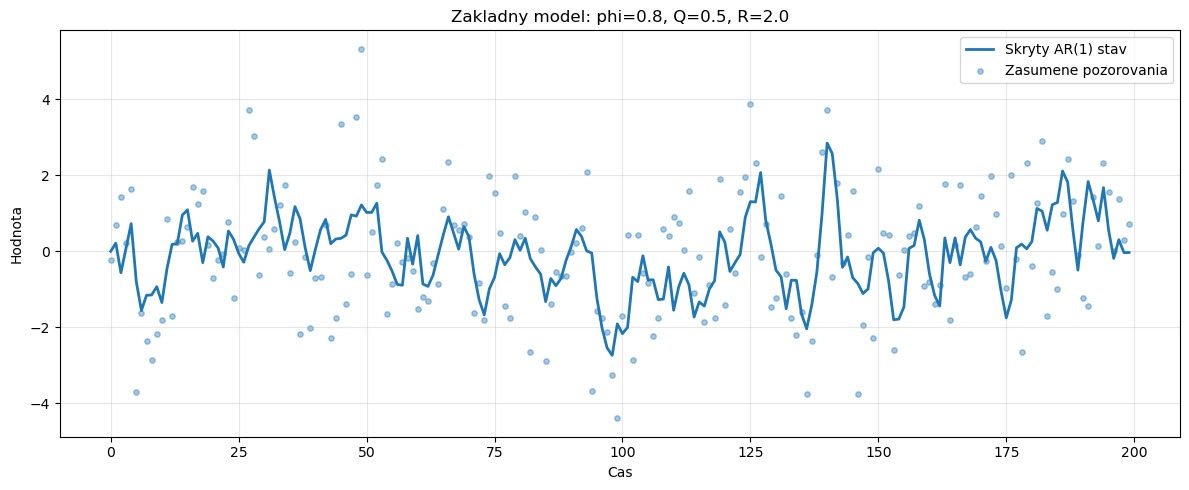

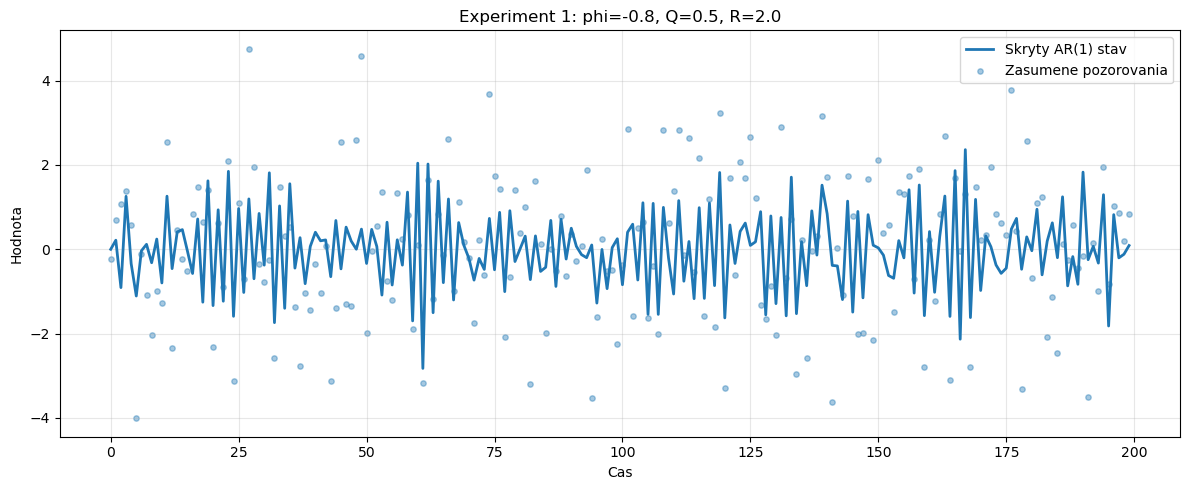

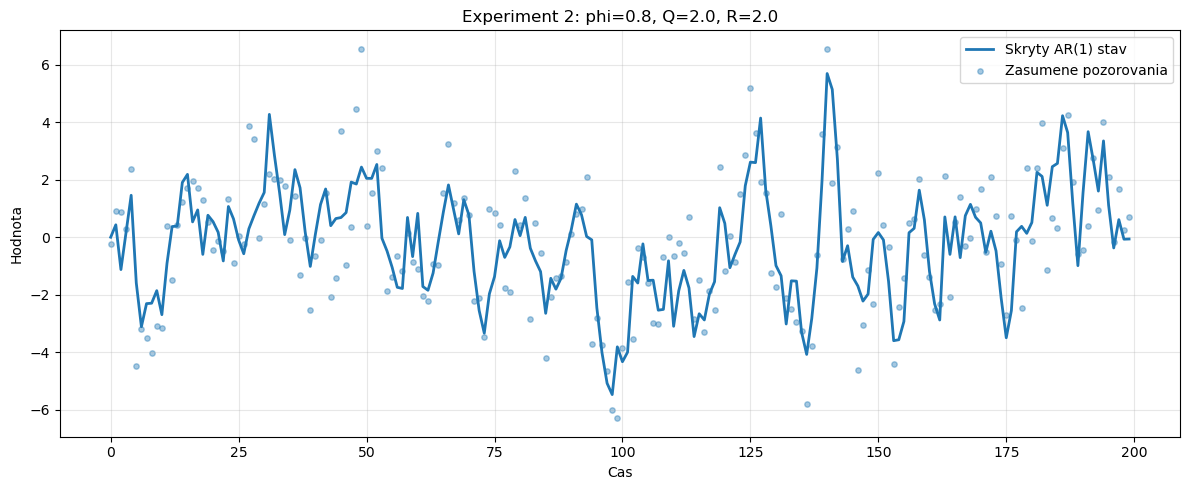

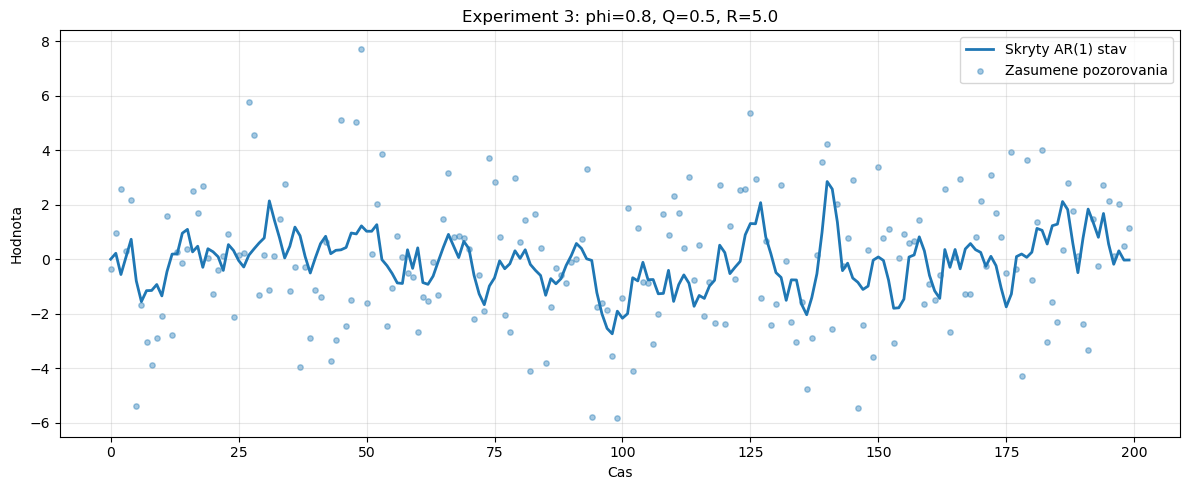

In [12]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Parametre stavového modelu
n = 200
phi = 0.8
Q = 0.5
R = 2.0

# 2. Simulacia skryteho AR(1) stavu
def simulate_state_model(phi, Q, R, n=200, seed=42):
    rng = np.random.default_rng(seed)

    state = np.zeros(n)

    for t in range(1, n):
        w_t = rng.normal(0, np.sqrt(Q))

        # Stavova rovnica AR(1)
        state[t] = phi * state[t - 1] + w_t

    # 3. Vytvorenie zasumenych pozorovani
    v = rng.normal(0, np.sqrt(R), size=n)
    observations = state + v

    return state, observations


def plot_state_model(state, observations, title):
    plt.figure(figsize=(12, 5))

    plt.plot(
        state,
        label="Skryty AR(1) stav",
        linewidth=2
    )

    plt.scatter(
        range(len(observations)),
        observations,
        label="Zasumene pozorovania",
        alpha=0.4,
        s=15
    )

    plt.title(title)
    plt.xlabel("Cas")
    plt.ylabel("Hodnota")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# Zakladny model: phi = 0.8, Q = 0.5, R = 2.0
state, observations = simulate_state_model(
    phi=0.8, Q=0.5, R=2.0
)

plot_state_model(
    state,
    observations,
    "Zakladny model: phi=0.8, Q=0.5, R=2.0"
)


# Experiment 1: Zmena phi z 0.8 na -0.8
state_phi, observations_phi = simulate_state_model(
    phi=-0.8, Q=0.5, R=2.0
)

plot_state_model(
    state_phi,
    observations_phi,
    "Experiment 1: phi=-0.8, Q=0.5, R=2.0"
)


# Experiment 2: Zvysenie Q z 0.5 na 2.0
state_Q, observations_Q = simulate_state_model(
    phi=0.8, Q=2.0, R=2.0
)

plot_state_model(
    state_Q,
    observations_Q,
    "Experiment 2: phi=0.8, Q=2.0, R=2.0"
)


# Experiment 3: Zvysenie R z 2.0 na 5.0
state_R, observations_R = simulate_state_model(
    phi=0.8, Q=0.5, R=5.0
)

plot_state_model(
    state_R,
    observations_R,
    "Experiment 3: phi=0.8, Q=0.5, R=5.0"
)



## BONUS: 2 Body
1. Analyzuje dáta v súboroch energy.csv, Precious_Metals.csv, Technology.csv a na základe výsledkov rozhodnite, pre ktoré datasety je vhodný VAR a pre ktoré VECM. Aký kointegračný rank bol určený a čo to znamená?
2. Iba pre dataset, pre ktorý je vhodný VECM, vyberte počet lagov pomocou AIC, odhadnite VECM s určeným kointegračným rankom a vykonajte rolling-origin predikciu s horizontom 1 pozorovanie dopredu. Prečo vstupné dáta pre VECM sú premenné v ich pôvodných úrovniach namiesto ich prvých diferencií?
    - dáta nezabudnite rozdeliť a predikciu vykonajte na posledných troch mesiacoch
3. Porovnajte skutočné a predikované hodnoty na grafe a vypočítajte MAE a RMSE.

In [13]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import VECM, select_order, select_coint_rank
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

DATA_DIR = "data"                       # folder with the CSV files
FILES = {
    "Energy": "energy.csv",
    "Precious metals": "Precious_Metals.csv",
    "Technology": "Technology.csv",
}
MAX_LAGS = 10                           # maximum number of lags tried for AIC
ALPHA = 0.05                            # significance level
DET_ORDER = 0                           # constant term in the Johansen test
TEST_MONTHS = 3                         # forecast horizon: last three months

In [14]:
import os

def load_dataset(path):
    """Read a CSV, use the date column as index and keep numeric columns only."""
    raw = pd.read_csv(path)
    date_col = next((c for c in raw.columns if c.lower() in ("date", "datetime", "time", "timestamp")),
                    raw.columns[0])
    raw[date_col] = pd.to_datetime(raw[date_col], errors="coerce", utc=True).dt.tz_localize(None)
    raw = raw.dropna(subset=[date_col]).set_index(date_col).sort_index()
    raw = raw[~raw.index.duplicated(keep="first")]
    data = raw.apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")
    return data.dropna()

datasets = {name: load_dataset(os.path.join(DATA_DIR, f)) for name, f in FILES.items()}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, columns = {list(df.columns)}")
    print(f"   period {df.index.min().date()} - {df.index.max().date()}")

Energy: 731 rows, columns = ['Biomass', 'Geothermal']
   period 2024-01-01 - 2025-12-31
Precious metals: 1760 rows, columns = ['GLD', 'SLV']
   period 2017-01-03 - 2023-12-29
Technology: 1760 rows, columns = ['AAPL', 'GOOGL', 'MSFT']
   period 2017-01-03 - 2023-12-29


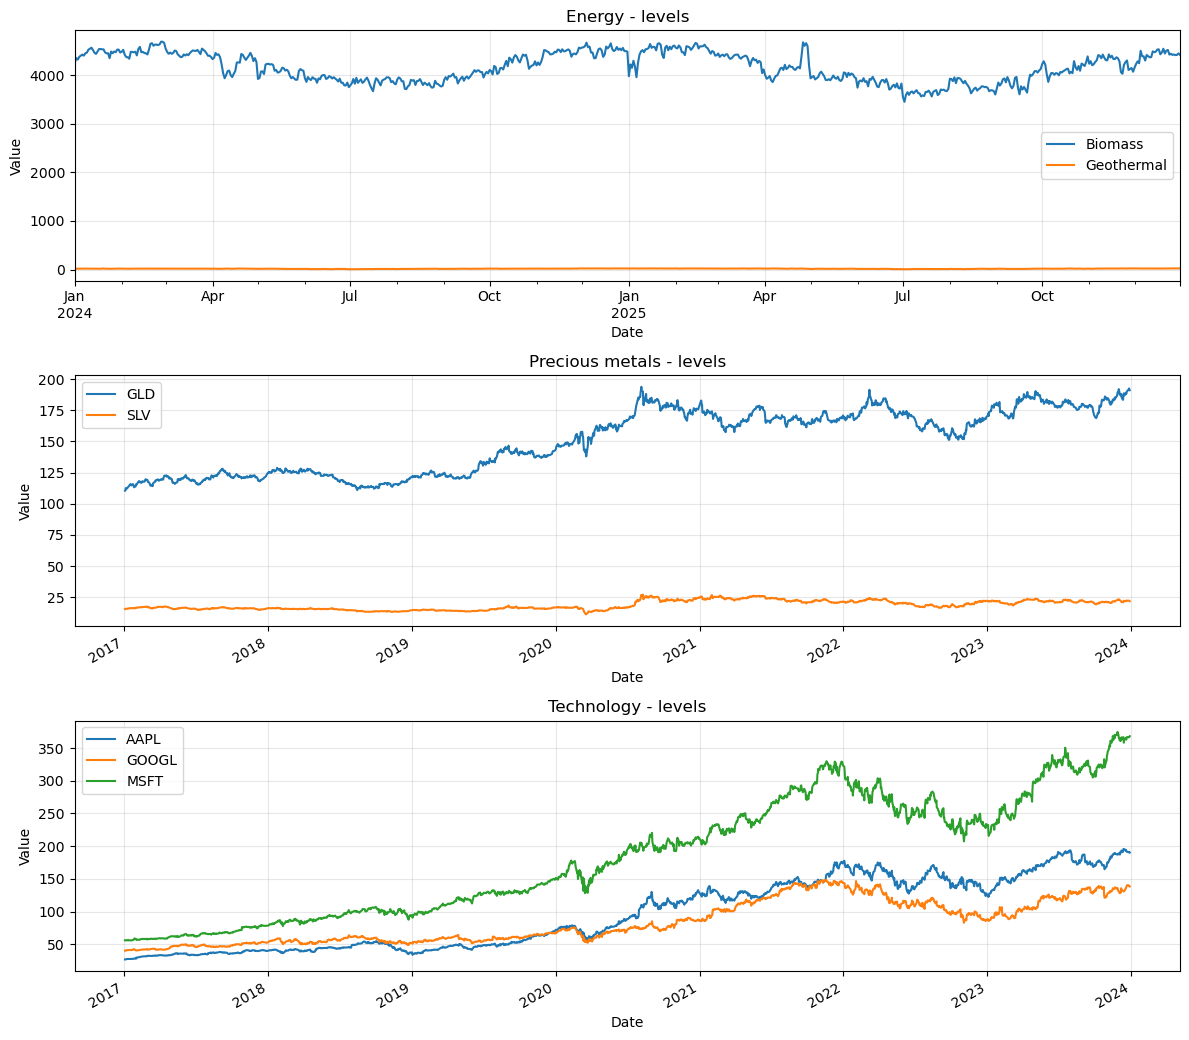

In [15]:
fig, axes = plt.subplots(len(datasets), 1, figsize=(12, 3.5 * len(datasets)))
for ax, (name, df) in zip(np.atleast_1d(axes), datasets.items()):
    df.plot(ax=ax)
    ax.set_title(f"{name} - levels")
    ax.set_xlabel("Date")
    ax.set_ylabel("Value")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
adf_rows = []
for name, df in datasets.items():
    for col in df.columns:
        p_level = adfuller(df[col])[1]
        p_diff = adfuller(df[col].diff().dropna())[1]
        adf_rows.append({
            "Dataset": name, "Series": col,
            "ADF p (levels)": p_level, "ADF p (1st difference)": p_diff,
            "Integration order": "I(0)" if p_level <= ALPHA else ("I(1)" if p_diff <= ALPHA else "I(2) or higher"),
        })
adf_df = pd.DataFrame(adf_rows)
print(adf_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

        Dataset     Series  ADF p (levels)  ADF p (1st difference) Integration order
         Energy    Biomass          0.2173                  0.0000              I(1)
         Energy Geothermal          0.4775                  0.0000              I(1)
Precious metals        GLD          0.7267                  0.0000              I(1)
Precious metals        SLV          0.3812                  0.0000              I(1)
     Technology       AAPL          0.9226                  0.0000              I(1)
     Technology      GOOGL          0.8960                  0.0000              I(1)
     Technology       MSFT          0.9560                  0.0000              I(1)


In [17]:
decision = {}
for name, df in datasets.items():
    k = df.shape[1]
    lag_sel = select_order(df, maxlags=MAX_LAGS, deterministic="co")
    k_ar_diff = max(lag_sel.aic, 1)
    rank_res = select_coint_rank(df, det_order=DET_ORDER, k_ar_diff=k_ar_diff,
                                 method="trace", signif=ALPHA)
    rank = rank_res.rank

    stationary_levels = (adf_df[adf_df["Dataset"] == name]["Integration order"] == "I(0)").all()
    if stationary_levels or rank == k:
        model_type = "VAR (levels)"
    elif rank == 0:
        model_type = "VAR (first differences)"
    else:
        model_type = "VECM"
    decision[name] = {"rank": rank, "k": k, "k_ar_diff": k_ar_diff, "model": model_type}

    print("=" * 70)
    print(f"{name}  (k = {k} series, k_ar_diff by AIC = {k_ar_diff})")
    print(rank_res.summary())
    print(f"-> cointegration rank = {rank}  ->  {model_type}")

Energy  (k = 2 series, k_ar_diff by AIC = 5)
Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   2          33.27          15.49
  1   2          3.302          3.841
-------------------------------------
-> cointegration rank = 1  ->  VECM
Precious metals  (k = 2 series, k_ar_diff by AIC = 2)
Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   2          11.94          15.49
-------------------------------------
-> cointegration rank = 0  ->  VAR (first differences)
Technology  (k = 3 series, k_ar_diff by AIC = 9)
Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   3          15.76          29.80
-------------------------------------
-> cointegration rank

In [18]:
summary = pd.DataFrame(decision).T[["k", "k_ar_diff", "rank", "model"]]
summary.columns = ["Number of series", "Lags (AIC, diff)", "Cointegration rank", "Suitable model"]
summary

,Number of series,"Lags (AIC, diff)",Cointegration rank,Suitable model
Energy,2,5,1,VECM
Precious metals,2,2,0,VAR (first differences)
Technology,3,9,0,VAR (first differences)


In [19]:
vecm_names = [n for n, d in decision.items() if d["model"] == "VECM"]
print("Datasets suitable for VECM:", vecm_names)

splits = {}
for name in vecm_names:
    df = datasets[name]
    cutoff = df.index.max() - pd.DateOffset(months=TEST_MONTHS)
    train = df[df.index <= cutoff]
    test = df[df.index > cutoff]
    splits[name] = (train, test)
    print(f"{name}: train {train.index.min().date()} - {train.index.max().date()} ({len(train)} obs), "
          f"test {test.index.min().date()} - {test.index.max().date()} ({len(test)} obs)")

Datasets suitable for VECM: ['Energy']
Energy: train 2024-01-01 - 2025-09-30 (639 obs), test 2025-10-01 - 2025-12-31 (92 obs)


In [20]:
models = {}
for name in vecm_names:
    train, test = splits[name]
    lag_sel = select_order(train, maxlags=MAX_LAGS, deterministic="co")
    k_ar_diff = max(lag_sel.aic, 1)
    rank = select_coint_rank(train, det_order=DET_ORDER, k_ar_diff=k_ar_diff,
                             method="trace", signif=ALPHA).rank
    print(f"{name}: AIC lag selection -> k_ar_diff = {k_ar_diff}, cointegration rank on training data = {rank}")
    print(lag_sel.summary())

    fit = VECM(train, k_ar_diff=k_ar_diff, coint_rank=rank, deterministic="co").fit()
    print(fit.summary())
    models[name] = {"k_ar_diff": k_ar_diff, "rank": rank}

Energy: AIC lag selection -> k_ar_diff = 4, cointegration rank on training data = 2
 VECM Order Selection (* highlights the minimums) 
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        8.856      8.912*       7015.       8.878
1        8.861       8.946       7052.       8.894
2        8.830       8.943       6835.      8.874*
3        8.830       8.972       6839.       8.885
4       8.829*       8.999      6830.*       8.895
5        8.834       9.032       6865.       8.911
6        8.841       9.068       6915.       8.929
7        8.841       9.096       6913.       8.940
8        8.842       9.125       6921.       8.952
9        8.851       9.162       6982.       8.972
10       8.855       9.194       7007.       8.986
--------------------------------------------------
Det. terms outside the coint. relation & lagged endog. parameters for equation Biomass
                    coef    std err          z      P>|z|      [

In [21]:
forecasts = {}
for name in vecm_names:
    train, test = splits[name]
    full = datasets[name]
    k_ar_diff, rank = models[name]["k_ar_diff"], models[name]["rank"]

    preds = []
    for t in test.index:
        history = full[full.index < t]
        fit = VECM(history, k_ar_diff=k_ar_diff, coint_rank=rank, deterministic="co").fit()
        preds.append(fit.predict(steps=1)[0])
    forecasts[name] = pd.DataFrame(preds, index=test.index, columns=test.columns)
    print(f"{name}: {len(preds)} one-step forecasts done")

Energy: 92 one-step forecasts done


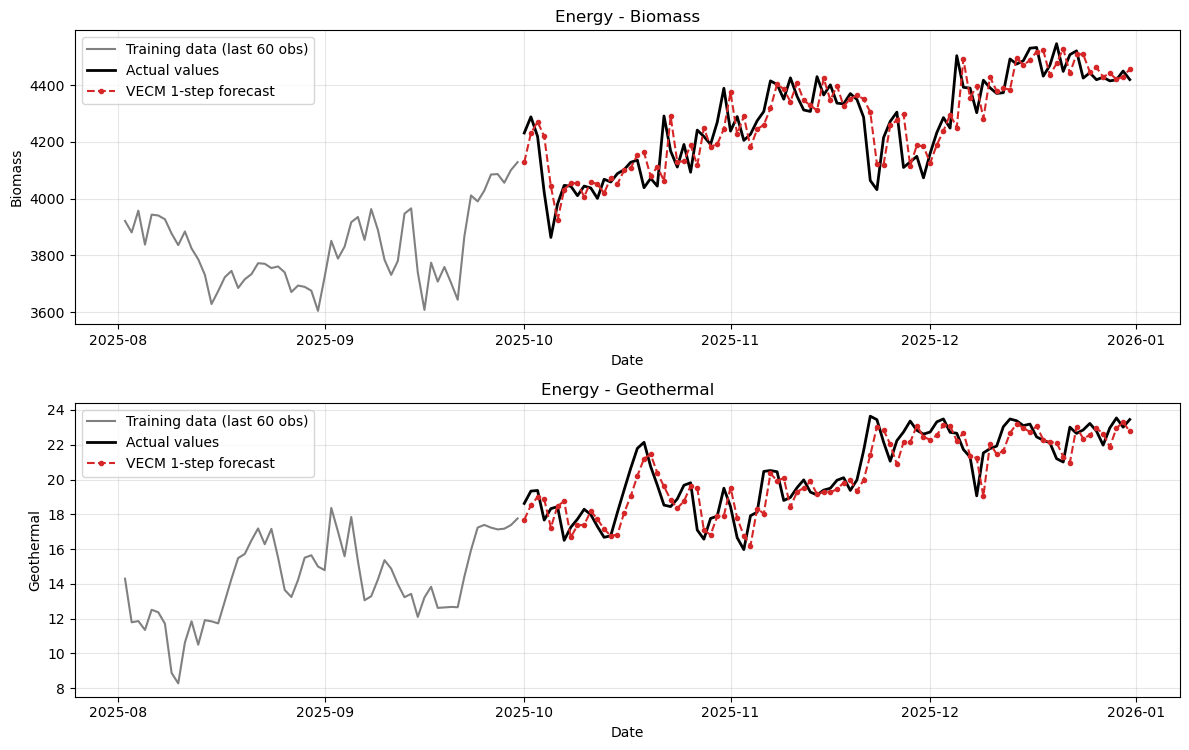

Forecast accuracy - Energy
    Series     MAE    RMSE  MAE naive  RMSE naive
   Biomass 61.3945 82.2108    63.8808     85.0116
Geothermal  0.7649  0.9771     0.7467      0.9788


In [22]:
for name in vecm_names:
    train, test = splits[name]
    pred = forecasts[name]

    cols = list(test.columns)
    fig, axes = plt.subplots(len(cols), 1, figsize=(12, 3.8 * len(cols)), squeeze=False)
    for ax, col in zip(axes[:, 0], cols):
        ax.plot(train[col].iloc[-60:], color="gray", label="Training data (last 60 obs)")
        ax.plot(test[col], color="black", linewidth=2, label="Actual values")
        ax.plot(pred[col], color="tab:red", linestyle="--", marker="o", markersize=3, label="VECM 1-step forecast")
        ax.set_title(f"{name} - {col}")
        ax.set_xlabel("Date")
        ax.set_ylabel(col)
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    rows = []
    for col in cols:
        rows.append({
            "Series": col,
            "MAE": mean_absolute_error(test[col], pred[col]),
            "RMSE": np.sqrt(mean_squared_error(test[col], pred[col])),
            "MAE naive": mean_absolute_error(test[col], full_shift := pd.concat([train, test])[col].shift(1).loc[test.index]),
            "RMSE naive": np.sqrt(mean_squared_error(test[col], full_shift)),
        })
    metrics = pd.DataFrame(rows)
    print(f"Forecast accuracy - {name}")
    print(metrics.to_string(index=False, float_format=lambda v: f"{v:.4f}"))